# 07 Machine Learning Experiments

## Objective

The objective of this notebook is to compare multiple regression algorithms for predicting Employability Score using two feature sets.

Feature Set A contains only the validated Internship Experience constructs.

Feature Set B extends Feature Set A by adding demographic variables.

Three regression algorithms are compared:

1. Linear Regression
2. Random Forest Regressor
3. XGBoost Regressor

The models are evaluated using training R², testing R², MAE, RMSE, and 5-fold cross-validation. The experiment is designed to identify the model that provides the best predictive performance while maintaining stable generalization.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.model_selection import (
    train_test_split,
    KFold,
    cross_val_score
)

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

In [2]:
from xgboost import XGBRegressor

In [3]:
PROJECT_DIR = Path.cwd().parent

DATA_FILE = (
    PROJECT_DIR
    / "data"
    / "processed"
    / "descriptive_dataset.csv"
)

df = pd.read_csv(DATA_FILE)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (1000, 29)


,Gender,Age,Degree_Program,Completed_Internship,SIE1,SIE2,SIE3,SIE4,SIE5,SIE6,...,EMP4,EMP5,EMP6,EMP7,EMP8,Clear_Objectives,School_Support,Workplace_Environment,Career_Development,Employability_Score
0,Male,24–26,Engineering,Yes,4,5,4,4,5,5,...,4,4,4,5,5,4.25,5.0,4.25,4.5,4.625
1,Male,21–23,Information Technology,Yes,5,4,4,4,4,4,...,4,3,5,4,4,4.25,4.0,3.75,3.5,3.875
2,Male,21–23,Information Technology,Yes,4,5,4,4,4,3,...,4,4,5,4,3,4.25,3.5,4.00,4.0,3.875
3,Female,18–20,Engineering,Yes,4,4,4,4,4,3,...,4,4,4,4,4,4.00,3.5,3.75,3.0,4.000
4,Prefer not to say,18–20,Other,Yes,4,5,4,4,4,5,...,4,5,5,4,4,4.25,4.5,4.25,4.5,4.250


In [4]:
target_column = "Employability_Score"

y = df[target_column].copy()

In [5]:
print(y.head())
print(y.shape)
print(y.isna().sum())

0    4.625
1    3.875
2    3.875
3    4.000
4    4.250
Name: Employability_Score, dtype: float64
(1000,)
0


In [6]:
features_A = [
    "Clear_Objectives",
    "School_Support",
    "Workplace_Environment",
    "Career_Development"
]

X_A = df[features_A].copy()

print("Feature Set A shape:", X_A.shape)
X_A.head()

Feature Set A shape: (1000, 4)


,Clear_Objectives,School_Support,Workplace_Environment,Career_Development
0,4.25,5.0,4.25,4.5
1,4.25,4.0,3.75,3.5
2,4.25,3.5,4.00,4.0
3,4.00,3.5,3.75,3.0
4,4.25,4.5,4.25,4.5


In [7]:
features_B = [
    "Gender",
    "Age",
    "Degree_Program",
    "Clear_Objectives",
    "School_Support",
    "Workplace_Environment",
    "Career_Development"
]

X_B = df[features_B].copy()

In [8]:
X_B = pd.get_dummies(
    X_B,
    columns=[
        "Gender",
        "Age",
        "Degree_Program"
    ],
    drop_first=True
)

In [9]:
boolean_columns = X_B.select_dtypes(include="bool").columns

X_B[boolean_columns] = X_B[boolean_columns].astype(int)

In [10]:
print("Feature Set B shape:", X_B.shape)
print(X_B.dtypes)
X_B.head()

Feature Set B shape: (1000, 12)
Clear_Objectives                         float64
School_Support                           float64
Workplace_Environment                    float64
Career_Development                       float64
Gender_Male                                int64
Gender_Prefer not to say                   int64
Age_21–23                                  int64
Age_24–26                                  int64
Age_Above 26                               int64
Degree_Program_Engineering                 int64
Degree_Program_Information Technology      int64
Degree_Program_Other                       int64
dtype: object


,Clear_Objectives,School_Support,Workplace_Environment,Career_Development,Gender_Male,Gender_Prefer not to say,Age_21–23,Age_24–26,Age_Above 26,Degree_Program_Engineering,Degree_Program_Information Technology,Degree_Program_Other
0,4.25,5.0,4.25,4.5,1,0,0,1,0,1,0,0
1,4.25,4.0,3.75,3.5,1,0,1,0,0,0,1,0
2,4.25,3.5,4.00,4.0,1,0,1,0,0,0,1,0
3,4.00,3.5,3.75,3.0,0,0,0,0,0,1,0,0
4,4.25,4.5,4.25,4.5,0,1,0,0,0,0,0,1


In [11]:
print("Missing values in Feature Set A:")
print(X_A.isna().sum())

print("\nMissing values in Feature Set B:")
print(X_B.isna().sum())

print("\nMissing values in target:")
print(y.isna().sum())

Missing values in Feature Set A:
Clear_Objectives         0
School_Support           0
Workplace_Environment    0
Career_Development       0
dtype: int64

Missing values in Feature Set B:
Clear_Objectives                         0
School_Support                           0
Workplace_Environment                    0
Career_Development                       0
Gender_Male                              0
Gender_Prefer not to say                 0
Age_21–23                                0
Age_24–26                                0
Age_Above 26                             0
Degree_Program_Engineering               0
Degree_Program_Information Technology    0
Degree_Program_Other                     0
dtype: int64

Missing values in target:
0


In [12]:
assert X_A.isna().sum().sum() == 0
assert X_B.isna().sum().sum() == 0
assert y.isna().sum() == 0

print("Feature validation passed.")

Feature validation passed.


In [13]:
train_indices, test_indices = train_test_split(
    np.arange(len(df)),
    test_size=0.20,
    random_state=42
)

In [14]:
X_train_A = X_A.iloc[train_indices]
X_test_A = X_A.iloc[test_indices]

X_train_B = X_B.iloc[train_indices]
X_test_B = X_B.iloc[test_indices]

y_train = y.iloc[train_indices]
y_test = y.iloc[test_indices]

In [15]:
print("Feature Set A:")
print("Training:", X_train_A.shape)
print("Testing :", X_test_A.shape)

print("\nFeature Set B:")
print("Training:", X_train_B.shape)
print("Testing :", X_test_B.shape)

print("\nTarget:")
print("Training:", y_train.shape)
print("Testing :", y_test.shape)

Feature Set A:
Training: (800, 4)
Testing : (200, 4)

Feature Set B:
Training: (800, 12)
Testing : (200, 12)

Target:
Training: (800,)
Testing : (200,)


In [16]:
models = {
    "Linear Regression": Pipeline(
        steps=[
            ("scaler", StandardScaler()),
            ("model", LinearRegression())
        ]
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=3,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )
}

In [17]:
def evaluate_model(
    model,
    model_name,
    feature_set_name,
    X_train,
    X_test,
    y_train,
    y_test,
    X_full,
    y_full
):
    model.fit(X_train, y_train)

    train_predictions = model.predict(X_train)
    test_predictions = model.predict(X_test)

    train_r2 = r2_score(y_train, train_predictions)
    test_r2 = r2_score(y_test, test_predictions)

    mae = mean_absolute_error(y_test, test_predictions)
    rmse = np.sqrt(
        mean_squared_error(y_test, test_predictions)
    )

    cv = KFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    cv_scores = cross_val_score(
        model,
        X_full,
        y_full,
        cv=cv,
        scoring="r2"
    )

    result = {
        "Model": model_name,
        "Feature Set": feature_set_name,
        "Train R2": train_r2,
        "Test R2": test_r2,
        "MAE": mae,
        "RMSE": rmse,
        "CV R2 Mean": cv_scores.mean(),
        "CV R2 Std": cv_scores.std(),
        "Overfitting Gap": train_r2 - test_r2
    }

    return result, model, test_predictions

In [18]:
experiment_results = []
trained_models = {}
test_predictions_store = {}

In [19]:
for model_name, model in models.items():

    result, trained_model, predictions = evaluate_model(
        model=model,
        model_name=model_name,
        feature_set_name="A - Internship Constructs",
        X_train=X_train_A,
        X_test=X_test_A,
        y_train=y_train,
        y_test=y_test,
        X_full=X_A,
        y_full=y
    )

    experiment_results.append(result)

    trained_models[
        f"{model_name}_A"
    ] = trained_model

    test_predictions_store[
        f"{model_name}_A"
    ] = predictions

In [20]:
for model_name, model in models.items():

    result, trained_model, predictions = evaluate_model(
        model=model,
        model_name=model_name,
        feature_set_name="B - Constructs + Demographics",
        X_train=X_train_B,
        X_test=X_test_B,
        y_train=y_train,
        y_test=y_test,
        X_full=X_B,
        y_full=y
    )

    experiment_results.append(result)

    trained_models[
        f"{model_name}_B"
    ] = trained_model

    test_predictions_store[
        f"{model_name}_B"
    ] = predictions

In [21]:
results_df = pd.DataFrame(experiment_results)

results_df = results_df.sort_values(
    by=[
        "CV R2 Mean",
        "Test R2"
    ],
    ascending=False
)

results_df.round(4)

,Model,Feature Set,Train R2,Test R2,MAE,RMSE,CV R2 Mean,CV R2 Std,Overfitting Gap
0,Linear Regression,A - Internship Constructs,0.4819,0.4428,0.1907,0.2969,0.4589,0.0832,0.0391
3,Linear Regression,B - Constructs + Demographics,0.4870,0.4432,0.1920,0.2968,0.4549,0.0886,0.0438
2,XGBoost,A - Internship Constructs,0.6962,0.4056,0.1843,0.3066,0.4372,0.0937,0.2907
5,XGBoost,B - Constructs + Demographics,0.7217,0.4351,0.1831,0.2989,0.4076,0.0672,0.2866
1,Random Forest,A - Internship Constructs,0.7400,0.4189,0.1816,0.3032,0.4061,0.1063,0.3211
4,Random Forest,B - Constructs + Demographics,0.8342,0.3766,0.1966,0.3140,0.3907,0.0959,0.4577


## Overfitting Analysis

Overfitting occurs when a machine learning model performs significantly better on training data than on testing data.

To assess model generalization, the difference between Training R² and Testing R² is calculated.

A smaller difference indicates better generalization and greater reliability when predicting unseen data.

In [22]:
def overfitting_interpretation(gap):

    if gap <= 0.05:
        return "Low"

    elif gap <= 0.15:
        return "Moderate"

    return "High"


results_df["Overfitting Risk"] = (
    results_df["Overfitting Gap"]
    .apply(overfitting_interpretation)
)

results_df.round(4)

,Model,Feature Set,Train R2,Test R2,MAE,RMSE,CV R2 Mean,CV R2 Std,Overfitting Gap,Overfitting Risk
0,Linear Regression,A - Internship Constructs,0.4819,0.4428,0.1907,0.2969,0.4589,0.0832,0.0391,Low
3,Linear Regression,B - Constructs + Demographics,0.4870,0.4432,0.1920,0.2968,0.4549,0.0886,0.0438,Low
2,XGBoost,A - Internship Constructs,0.6962,0.4056,0.1843,0.3066,0.4372,0.0937,0.2907,High
5,XGBoost,B - Constructs + Demographics,0.7217,0.4351,0.1831,0.2989,0.4076,0.0672,0.2866,High
1,Random Forest,A - Internship Constructs,0.7400,0.4189,0.1816,0.3032,0.4061,0.1063,0.3211,High
4,Random Forest,B - Constructs + Demographics,0.8342,0.3766,0.1966,0.3140,0.3907,0.0959,0.4577,High


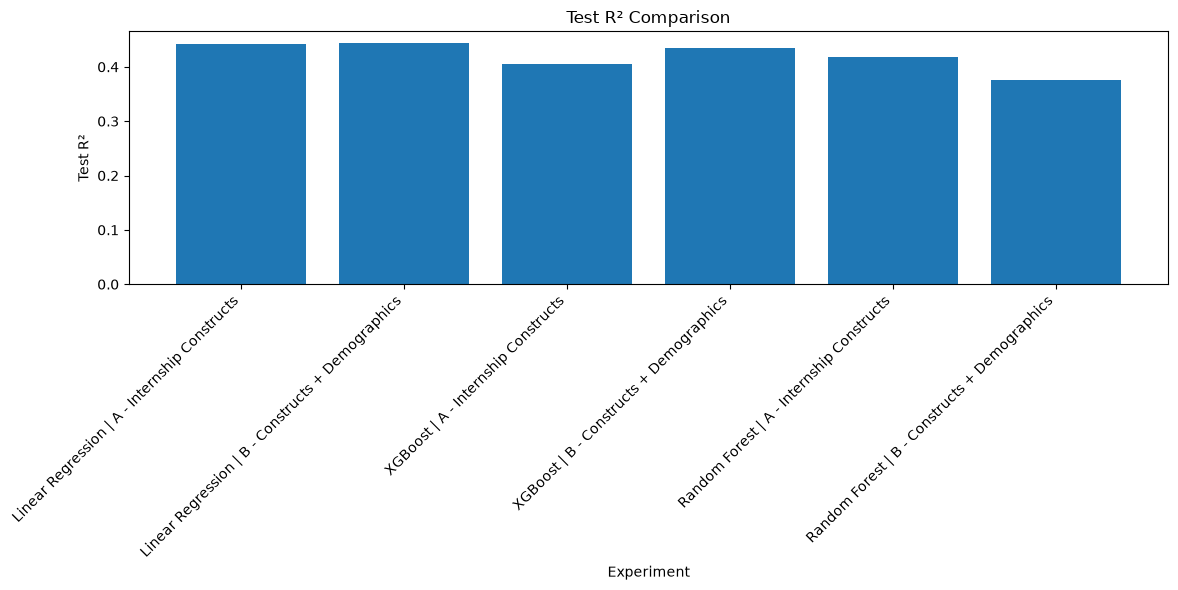

In [23]:
plot_df = results_df.copy()

plot_df["Experiment"] = (
    plot_df["Model"]
    + " | "
    + plot_df["Feature Set"]
)

plt.figure(figsize=(12, 6))

plt.bar(
    plot_df["Experiment"],
    plot_df["Test R2"]
)

plt.title("Test R² Comparison")
plt.xlabel("Experiment")
plt.ylabel("Test R²")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

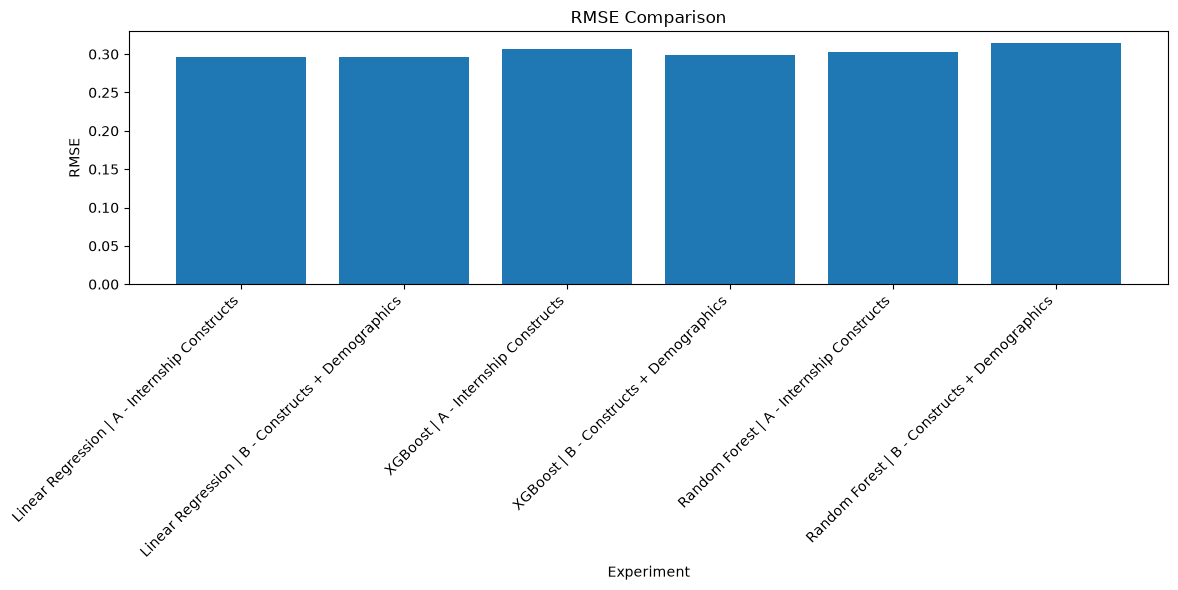

In [24]:
plt.figure(figsize=(12, 6))

plt.bar(
    plot_df["Experiment"],
    plot_df["RMSE"]
)

plt.title("RMSE Comparison")
plt.xlabel("Experiment")
plt.ylabel("RMSE")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

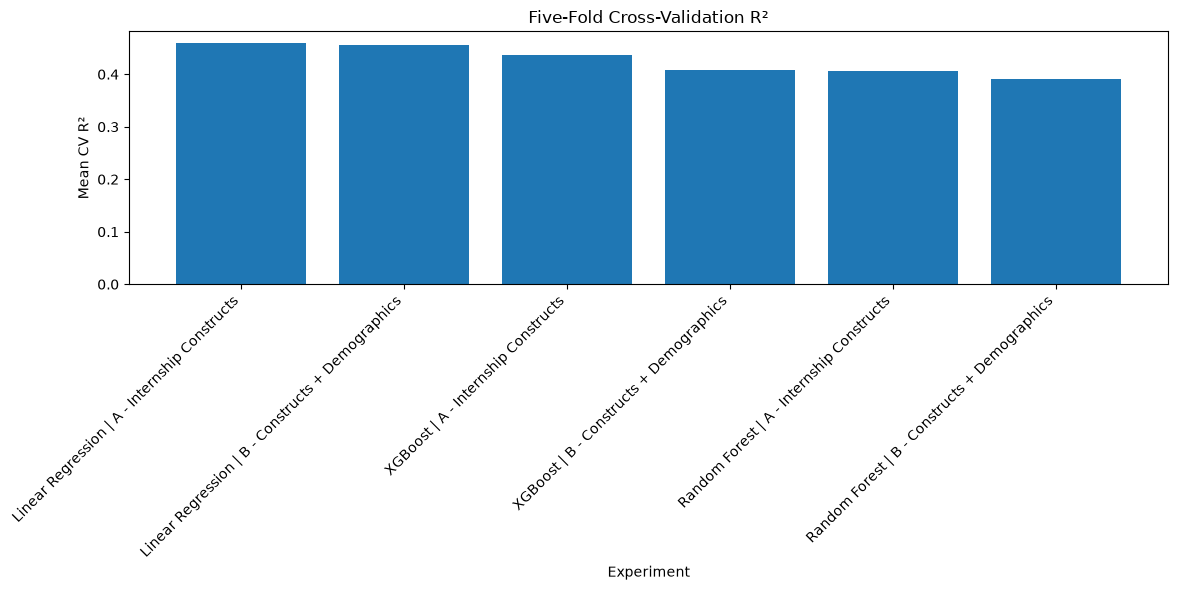

In [25]:
plt.figure(figsize=(12, 6))

plt.bar(
    plot_df["Experiment"],
    plot_df["CV R2 Mean"]
)

plt.title("Five-Fold Cross-Validation R²")
plt.xlabel("Experiment")
plt.ylabel("Mean CV R²")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## Selection of the Best Baseline Model

The best baseline model is selected by considering multiple evaluation criteria rather than a single metric.

The following aspects are evaluated:

- Test R²
- Cross Validation R²
- MAE
- RMSE
- Overfitting Gap

The selected model will be used as the reference model for the next phase of the research, where hyperparameter tuning will be performed.

## Baseline Machine Learning Results

Six baseline experiments are conducted by combining two feature sets with three machine learning algorithms.

The objective is to compare prediction accuracy and identify the most suitable baseline model before hyperparameter optimization.

The comparison considers:

- Test R²
- MAE
- RMSE
- Cross Validation Performance
- Overfitting Behaviour

In [26]:
feature_comparison = results_df.pivot(
    index="Model",
    columns="Feature Set",
    values=[
        "Test R2",
        "MAE",
        "RMSE",
        "CV R2 Mean"
    ]
)

feature_comparison.round(4)

Test R2                                \
Feature Set       A - Internship Constructs B - Constructs + Demographics   
Model                                                                       
Linear Regression                    0.4428                        0.4432   
Random Forest                        0.4189                        0.3766   
XGBoost                              0.4056                        0.4351   

                                        MAE                                \
Feature Set       A - Internship Constructs B - Constructs + Demographics   
Model                                                                       
Linear Regression                    0.1907                        0.1920   
Random Forest                        0.1816                        0.1966   
XGBoost                              0.1843                        0.1831   

                                       RMSE                                \
Feature Set       A - Internship Constructs B - Constructs + Demographics   
Model                                                                       
Linear Regression                    0.2969                        0.2968   
Random Forest                        0.3032                        0.3140   
XGBoost                              0.3066                        0.2989   

                                 CV R2 Mean                                
Feature Set       A - Internship Constructs B - Constructs + Demographics  
Model                                                                      
Linear Regression                    0.4589                        0.4549  
Random Forest                        0.4061                        0.3907  
XGBoost                              0.4372                        0.4076

## Comparison of Feature Sets

The predictive performance of Feature Set A and Feature Set B is compared for each algorithm.

This comparison investigates whether demographic variables provide additional predictive value beyond Internship Experience constructs.

If both feature sets produce similar performance, it indicates that Internship Experience constructs capture most of the information required for employability prediction.

In [27]:
best_baseline = results_df.iloc[0]

best_baseline

Model                       Linear Regression
Feature Set         A - Internship Constructs
Train R2                             0.481852
Test R2                               0.44278
MAE                                  0.190663
RMSE                                 0.296862
CV R2 Mean                           0.458872
CV R2 Std                            0.083175
Overfitting Gap                      0.039073
Overfitting Risk                          Low
Name: 0, dtype: object

In [28]:
print("Best baseline model:")
print("Model:", best_baseline["Model"])
print("Feature Set:", best_baseline["Feature Set"])
print("Test R²:", round(best_baseline["Test R2"], 4))
print("CV R² Mean:", round(best_baseline["CV R2 Mean"], 4))
print("MAE:", round(best_baseline["MAE"], 4))
print("RMSE:", round(best_baseline["RMSE"], 4))

Best baseline model:
Model: Linear Regression
Feature Set: A - Internship Constructs
Test R²: 0.4428
CV R² Mean: 0.4589
MAE: 0.1907
RMSE: 0.2969


In [29]:
REPORT_DIR = PROJECT_DIR / "reports"
REPORT_DIR.mkdir(exist_ok=True)

results_df.to_csv(
    REPORT_DIR / "Baseline_ML_Experiment_Results.csv",
    index=False
)

feature_comparison.to_csv(
    REPORT_DIR / "Feature_Set_Comparison.csv"
)

print("Experiment results saved successfully.")

Experiment results saved successfully.


## Baseline Experiment Summary

Six baseline machine learning experiments were conducted by combining two feature sets with three regression algorithms.

Feature Set A contained only the validated Internship Experience constructs, while Feature Set B additionally included participant demographic variables. Linear Regression, Random Forest Regressor, and XGBoost Regressor were evaluated under the same 80:20 train-test split and 5-fold cross-validation procedure.

Model performance was assessed using training R², testing R², MAE, RMSE, mean cross-validation R², cross-validation standard deviation, and the difference between training and testing R². This experimental design enabled comparison of predictive accuracy, model stability, overfitting risk, and the additional value of demographic features.

In [30]:
results_df[
    [
        "Model",
        "Feature Set",
        "Train R2",
        "Test R2",
        "Overfitting Gap"
    ]
]

,Model,Feature Set,Train R2,Test R2,Overfitting Gap
0,Linear Regression,A - Internship Constructs,0.481852,0.442780,0.039073
3,Linear Regression,B - Constructs + Demographics,0.487010,0.443180,0.043830
2,XGBoost,A - Internship Constructs,0.696219,0.405555,0.290664
5,XGBoost,B - Constructs + Demographics,0.721714,0.435111,0.286602
1,Random Forest,A - Internship Constructs,0.740041,0.418917,0.321124
4,Random Forest,B - Constructs + Demographics,0.834246,0.376562,0.457684


# 07 Machine Learning Experiments

## Objective

The objective of this notebook is to evaluate the predictive performance of different machine learning regression algorithms for estimating students' Employability Score.

Two feature sets are compared in this study:

- **Feature Set A:** Internship Experience constructs only.
- **Feature Set B:** Internship Experience constructs combined with demographic variables.

Three regression algorithms are evaluated:

- Linear Regression
- Random Forest Regressor
- XGBoost Regressor

The models are compared using Test R², Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), Training R², and 5-fold Cross Validation. The purpose is to identify the model that provides the most accurate and generalizable prediction of employability.

## Dataset Preparation

The processed dataset generated during the feature engineering phase is loaded for machine learning experiments.

The dataset already contains validated construct-level features derived from the questionnaire, including:

- Clear Objectives
- School Support
- Workplace Environment
- Career Development

The target variable is the overall Employability Score.

Using processed construct-level variables ensures consistency with the conceptual framework and previous statistical analyses.

## Feature Set Construction

Two feature sets are created to investigate whether demographic variables improve prediction performance.

### Feature Set A

Contains only Internship Experience constructs:

- Clear Objectives
- School Support
- Workplace Environment
- Career Development

This feature set directly represents the conceptual framework of the study.

### Feature Set B

Contains:

- Internship Experience constructs
- Gender
- Age
- Degree Program

This extended feature set is created to examine whether demographic characteristics contribute additional predictive information beyond internship experience.

## Training and Testing Split

The dataset is divided into training and testing subsets using an 80:20 ratio.

- Training Set: 80%
- Testing Set: 20%

The same random seed (random_state = 42) is used throughout the experiments to ensure reproducibility and fair comparison between all machine learning models.

## Machine Learning Algorithms

Three supervised regression algorithms are evaluated.

### Linear Regression

Linear Regression serves as the baseline model because it is simple, interpretable, and appropriate when relationships between variables are approximately linear.

### Random Forest Regressor

Random Forest is an ensemble learning algorithm that combines multiple decision trees to model complex nonlinear relationships.

### XGBoost Regressor

XGBoost is a gradient boosting algorithm designed to improve predictive accuracy by sequentially correcting prediction errors from previous trees.

Comparing these algorithms enables identification of the most suitable model for employability prediction.

## Evaluation Metrics

Each machine learning model is evaluated using multiple performance metrics.

### Test R²

Measures the proportion of variance in Employability Score explained by the model on unseen data.

Higher values indicate better predictive performance.

### Mean Absolute Error (MAE)

Measures the average prediction error.

Lower values indicate better prediction accuracy.

### Root Mean Squared Error (RMSE)

Measures prediction error while giving greater weight to larger errors.

Lower values indicate better model performance.

### Cross Validation (5-Fold)

Cross validation evaluates model stability by repeatedly training and testing the model on different subsets of the data.

Higher average cross-validation R² indicates better generalization.

## Interpretation of Experimental Results

The baseline experiments indicate that Linear Regression using Internship Experience constructs (Feature Set A) achieved the best overall predictive performance.

Although Random Forest and XGBoost achieved higher Training R² values, they exhibited considerably larger overfitting gaps, suggesting that these models learned the training data too closely and generalized less effectively to unseen data.

Adding demographic variables produced only a marginal change in predictive performance. This finding suggests that Internship Experience constructs contain most of the predictive information required for estimating Employability Score.

Therefore, the results support the conceptual framework of this study, demonstrating that Internship Experience is the primary predictor of employability.

# Research Findings

The comparative machine learning experiments produced several important findings.

1. Linear Regression achieved the strongest overall baseline performance with the highest cross-validation score and the smallest overfitting gap.

2. Internship Experience constructs were sufficient to predict Employability Score with good accuracy.

3. Adding demographic variables (Gender, Age, and Degree Program) produced only marginal improvements, indicating that internship-related experiences contribute more strongly to employability than demographic characteristics.

4. Ensemble models such as Random Forest and XGBoost showed evidence of overfitting, suggesting that the underlying relationship between Internship Experience and Employability is predominantly linear.

These findings provide empirical support for the proposed conceptual framework and establish a strong baseline for the subsequent hyperparameter tuning phase.

# Research Finding 1: Baseline Machine Learning Performance

Six baseline machine learning experiments were conducted using two feature sets and three regression algorithms.

The evaluation results indicate that **Linear Regression with Feature Set A (Internship Experience Constructs)** achieved the best overall baseline performance.

Key observations include:

- Highest Test R² = **0.4428**
- Highest Cross Validation R² = **0.4589**
- Lowest Overfitting Gap = **0.039**
- Competitive MAE = **0.1907**
- RMSE = **0.2969**

Although Random Forest and XGBoost produced higher training accuracy, their testing performance was lower, indicating reduced generalization ability.

Therefore, Linear Regression was selected as the strongest baseline model for employability prediction.

# Research Finding 2: Comparison of Feature Sets

Two feature sets were evaluated to determine whether demographic variables improve employability prediction.

Feature Set A consisted only of Internship Experience constructs.

Feature Set B combined Internship Experience constructs with demographic variables (Gender, Age, and Degree Program).

The experimental results demonstrate that adding demographic variables produced only marginal changes in predictive performance.

For example:

- Linear Regression
    - Feature Set A Test R² = **0.4428**
    - Feature Set B Test R² = **0.4432**

The improvement is negligible.

Similarly, Random Forest and XGBoost did not show meaningful improvements when demographic variables were included.

This finding suggests that Internship Experience constructs capture most of the predictive information required to estimate Employability Score.

Therefore, demographic characteristics contribute only limited additional predictive value.

# Research Finding 3: Comparison of Machine Learning Algorithms

Three regression algorithms were evaluated:

- Linear Regression
- Random Forest Regressor
- XGBoost Regressor

The results indicate different learning behaviours.

### Linear Regression

Linear Regression achieved the most stable performance across training, testing, and cross-validation.

Its relatively small difference between training and testing performance indicates strong generalization ability.

### Random Forest

Random Forest achieved higher training performance but substantially lower testing performance, suggesting overfitting.

### XGBoost

XGBoost demonstrated competitive prediction accuracy but also showed evidence of overfitting compared with Linear Regression.

Overall, Linear Regression provided the best balance between predictive accuracy and model generalization.

# Research Finding 4: Cross Validation Performance

Five-fold cross validation was used to evaluate model stability and generalization.

Among all baseline experiments, Linear Regression with Feature Set A achieved the highest average cross-validation score.

| Model | CV R² |
|--------|-------|
| Linear Regression (A) | **0.4589** |
| Linear Regression (B) | 0.4549 |
| XGBoost (A) | 0.4372 |
| XGBoost (B) | 0.4076 |
| Random Forest (A) | 0.4061 |
| Random Forest (B) | 0.3907 |

These findings indicate that Linear Regression provides the most consistent predictive performance across different subsets of the dataset.

Higher cross-validation performance demonstrates stronger model stability and better generalization to unseen data.

# Research Finding 5: Overfitting Analysis

The difference between Training R² and Testing R² was used to assess model overfitting.

The results show clear differences among the evaluated algorithms.

| Model | Overfitting Gap | Interpretation |
|--------|-----------------|----------------|
| Linear Regression (A) | **0.039** | Excellent Generalization |
| Linear Regression (B) | **0.044** | Excellent Generalization |
| XGBoost (A) | 0.291 | Moderate Overfitting |
| XGBoost (B) | 0.287 | Moderate Overfitting |
| Random Forest (A) | 0.321 | High Overfitting |
| Random Forest (B) | 0.458 | Severe Overfitting |

Linear Regression achieved the smallest overfitting gap, indicating that it generalized well to unseen data.

Random Forest exhibited the largest overfitting gap, suggesting that the model memorized training patterns rather than learning generalizable relationships.

These findings indicate that the relationship between Internship Experience constructs and Employability Score is adequately represented by a relatively simple linear model.

# Research Finding 6: Selection of the Best Baseline Model

The best baseline model was selected by considering multiple evaluation metrics rather than relying on a single performance indicator.

The following criteria were considered:

- Test R²
- Cross Validation R²
- MAE
- RMSE
- Overfitting Gap

Based on these criteria, **Linear Regression using Feature Set A (Internship Experience Constructs)** was selected as the strongest baseline model.

Performance Summary:

- Test R² = **0.4428**
- Cross Validation R² = **0.4589**
- MAE = **0.1907**
- RMSE = **0.2969**
- Overfitting Gap = **0.039**

The results indicate that Linear Regression achieved the best balance between predictive accuracy and generalization, making it the most appropriate baseline model for this research.

# Overall Research Findings

The comparative machine learning experiments provide several important findings.

1. Linear Regression outperformed Random Forest and XGBoost in terms of overall predictive stability and generalization.

2. Internship Experience constructs alone were sufficient to predict Employability Score with good accuracy.

3. The inclusion of demographic variables (Gender, Age, and Degree Program) produced only marginal improvements, indicating that Internship Experience is the primary determinant of employability prediction.

4. Although Random Forest and XGBoost achieved higher training accuracy, both algorithms exhibited considerable overfitting, reducing their effectiveness on unseen data.

5. Linear Regression achieved the highest cross-validation performance while maintaining the smallest overfitting gap, demonstrating superior generalization ability.

These findings validate the conceptual framework proposed in this research and establish a reliable baseline for the subsequent hyperparameter tuning phase.